Dans le cadre d'une enquête de fidélisation client, nous avons reçu la base de données Customer-Churn-Records.csv qui contient un ensemble d'information sur les clients d'une banque,
L'établissement bancaire souhaitant freiner l'attrition de sa clientéle.
L'objectif principal de cette analyse est de d'identifier les facteurs influençant le départ des clients.
En effet pour anticiper et limiter ces départs,nous allons développer un modele de classification prédictif.

1. STEP 1 : IMPORT DATA

In [139]:
# Importation des bibliothèques

import pandas as pd
import numpy as np 
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer, make_column_selector
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, accuracy_score
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix
import warnings
warnings.filterwarnings("ignore")

In [100]:
#Importation du fichier CSV

df = pd.read_csv("Customer-Churn-Records.csv")
df.head()

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Complain,Satisfaction Score,Card Type,Point Earned
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1,1,2,DIAMOND,464
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0,1,3,DIAMOND,456
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1,1,3,DIAMOND,377
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0,0,5,GOLD,350
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0,0,5,GOLD,425


2. STEP 2 : EDA

In [101]:
#Vérification des doublons 

Doublons = df.duplicated()
print(f"Y a-t-il des doublons ? : {Doublons.any()}")

Y a-t-il des doublons ? : False


In [102]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 18 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   RowNumber           10000 non-null  int64  
 1   CustomerId          10000 non-null  int64  
 2   Surname             10000 non-null  object 
 3   CreditScore         10000 non-null  int64  
 4   Geography           10000 non-null  object 
 5   Gender              10000 non-null  object 
 6   Age                 10000 non-null  int64  
 7   Tenure              10000 non-null  int64  
 8   Balance             10000 non-null  float64
 9   NumOfProducts       10000 non-null  int64  
 10  HasCrCard           10000 non-null  int64  
 11  IsActiveMember      10000 non-null  int64  
 12  EstimatedSalary     10000 non-null  float64
 13  Exited              10000 non-null  int64  
 14  Complain            10000 non-null  int64  
 15  Satisfaction Score  10000 non-null  int64  
 16  Card 

In [103]:
#Vérification des valeurs manquantes

print(df.isna().any())

RowNumber             False
CustomerId            False
Surname               False
CreditScore           False
Geography             False
Gender                False
Age                   False
Tenure                False
Balance               False
NumOfProducts         False
HasCrCard             False
IsActiveMember        False
EstimatedSalary       False
Exited                False
Complain              False
Satisfaction Score    False
Card Type             False
Point Earned          False
dtype: bool


RowNumber : C'est juste un index, sans signification pour le comportement du client.

CustomerId : Identifiant unique du client, utile pour l'identification mais n'a pas de pouvoir prédictif en soi.

Surname : Le nom de famille n'a aucune pertinence prédictive pour l'attrition

In [104]:
#Surppression des colonnes inutiles 

df_2 = df.drop(['RowNumber', 'CustomerId', 'Surname'], axis = 1)

df_2.head()

,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Complain,Satisfaction Score,Card Type,Point Earned
0,619,France,Female,42,2,0.00,1,1,1,101348.88,1,1,2,DIAMOND,464
1,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0,1,3,DIAMOND,456
2,502,France,Female,42,8,159660.80,3,1,0,113931.57,1,1,3,DIAMOND,377
3,699,France,Female,39,1,0.00,2,0,0,93826.63,0,0,5,GOLD,350
4,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0,0,5,GOLD,425


In [105]:
#affichage des principales statistiques

display(df_2.describe())

,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Complain,Satisfaction Score,Point Earned
count,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000
mean,650.528800,38.921800,5.012800,76485.889288,1.530200,0.70550,0.515100,100090.239881,0.203800,0.204400,3.013800,606.515100
std,96.653299,10.487806,2.892174,62397.405202,0.581654,0.45584,0.499797,57510.492818,0.402842,0.403283,1.405919,225.924839
min,350.000000,18.000000,0.000000,0.000000,1.000000,0.00000,0.000000,11.580000,0.000000,0.000000,1.000000,119.000000
25%,584.000000,32.000000,3.000000,0.000000,1.000000,0.00000,0.000000,51002.110000,0.000000,0.000000,2.000000,410.000000
50%,652.000000,37.000000,5.000000,97198.540000,1.000000,1.00000,1.000000,100193.915000,0.000000,0.000000,3.000000,605.000000
75%,718.000000,44.000000,7.000000,127644.240000,2.000000,1.00000,1.000000,149388.247500,0.000000,0.000000,4.000000,801.000000
max,850.000000,92.000000,10.000000,250898.090000,4.000000,1.00000,1.000000,199992.480000,1.000000,1.000000,5.000000,1000.000000


3. STEP 3 :  VISUALISATION

20,4% représente le pourcentage de clients partis de la banque tandis que les 79,6% réprésente les clients présents actuellement 

 Répartition des clients partis et présents 
Statut Client  Nombre de Clients  Pourcentage (%)
      Présent               7962            79.62
        Parti               2038            20.38

Total des clients: 10000


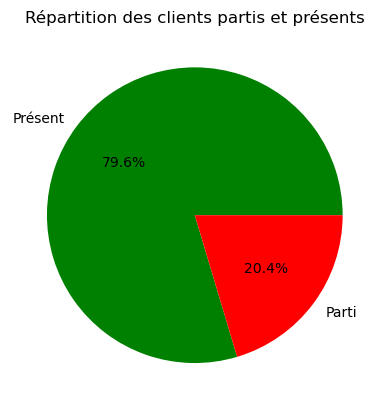

In [106]:
data = {
    'Statut Client': ['Présent', 'Parti'],
    'Nombre de Clients': [df['Exited'].value_counts()[0],df['Exited'].value_counts()[1]], 
    'Pourcentage (%)': [(df['Exited'].value_counts(normalize=True) * 100)[0], (df['Exited'].value_counts(normalize=True) * 100)[1]] 
}

print(" Répartition des clients partis et présents ")
print(pd.DataFrame(data).to_string(index=False)) 
print(f"\nTotal des clients: {df['Exited'].count()}")

plt.pie(df['Exited'].value_counts(), labels=['Présent', 'Parti'], autopct='%1.1f%%', colors=['green', 'red'])
plt.title('Répartition des clients partis et présents')
plt.show()

Le graphique repésente la répartition des clients présents et partis par tranche d'âge.

De 25 à 65 ans , nous avons une majorité de départs des clients sur ces 4 tranches d'âges. 

Néanmoins de 18 à 25 et de 65 a 85 , les clients sont plutôt fidèles a la banque.

De 45 a 55 ans , les clients sont majoritairement sur le départs , cela s'explique peut-être pour des raisons personnels (taux de crédit,...)

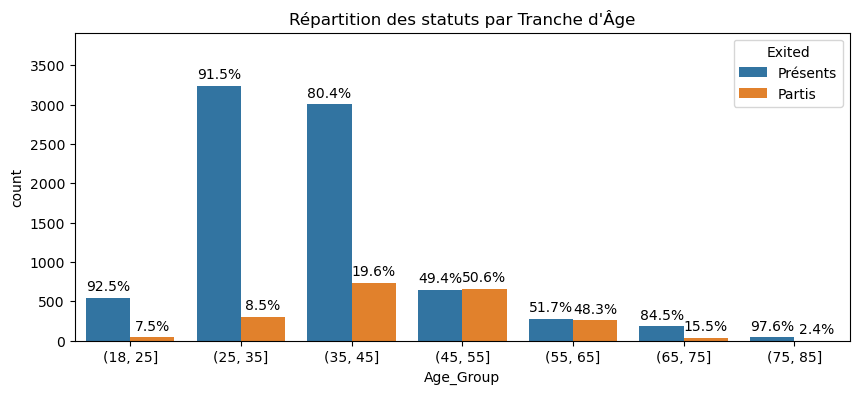

In [ ]:

df['Age_Group']= pd.cut(df['Age'], [18, 25, 35, 45, 55, 65, 75, 85] , ['18-24', '25-34', '35-44', '45-54', '55-64', '65-74', '75-84', '85+'])
# On calcule le total par tranche d'âge
total_par_age = df.groupby('Age_Group', observed=False)['Exited'].count()
# On calcule le nombre de partants par tranche d'âge
partis_par_age = df[df['Exited'] == 1].groupby('Age_Group', observed=False)['Exited'].count()
# On divise pour avoir le pourcentage de partants
pourcentage_partis = (partis_par_age / total_par_age) * 100

#  Création du graphique
plt.figure(figsize=(10, 4))
ax = sns.countplot(x='Age_Group', hue='Exited', data=df)

# Ajoute des pourcentages sur les barres
# On itère sur les conteneurs de barres (le premier = Présents, le deuxième = Partis)
for i, container in enumerate(ax.containers):
    if i == 0: # Barres bleues (Présents)
        # Le pourcentage des présents est 100% - le pourcentage des partis
        labels = [f'{100 - pourcentage_partis[cat]:.1f}%' for cat in total_par_age.index]
    else: # Barres oranges (Partis)
        # On utilise directement notre calcul de pourcentage
        labels = [f'{pourcentage_partis[cat]:.1f}%' for cat in total_par_age.index]
   
    # On ajoute les étiquettes au-dessus des barres
    ax.bar_label(container, labels=labels, label_type='edge', padding=3)

#  Personnalisation
plt.title("Répartition des statuts par Tranche d'Âge")
plt.legend(labels=['Présents', 'Partis'], title='Exited')
plt.ylim(0, ax.get_ylim()[1] * 1.15) # Pour ne pas couper les étiquettes
plt.show()

Analyse métier : Le probleme de rétention ne concerne pas les jeunes, ni les personnes agées. il concerne massivement les clients d'age moyen (35 à 65 ans)  
Ces client sont probablement à un stade de leur vie ou ils ont des besoins financiers importants (crédits, épargne, assurance) et ou ils sont la cible principale des offres des banues concurrentes  
S'ils ne sont pas satisfait ils partent  
Recommandation : Concentrer absolument toutes les campagnes de rétention et enquetes de satisfaction sur les clients agés entre 35 et 65 ans c'est la ou la banque perd le plus d'argent.

Les clients fidèles ne sont pas les plus acheteurs et ne sont pas non plus les premiers clients

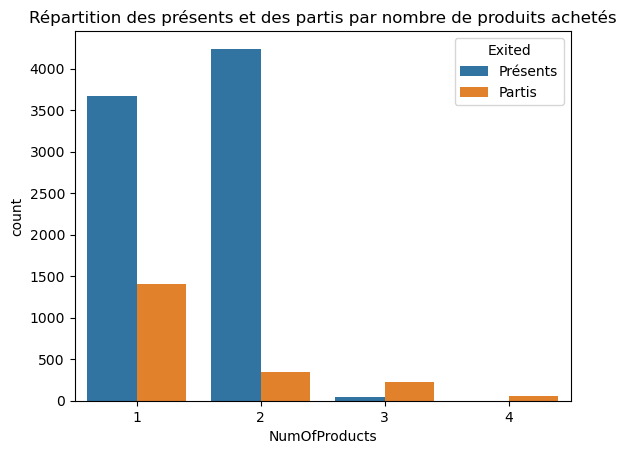

In [108]:
sns.countplot(x='NumOfProducts',hue='Exited',data=df)
plt.title("Répartition des présents et des partis par nombre de produits achetés")
new_labels = ['Présents', 'Partis'] 
plt.legend(labels=new_labels, title='Exited')
plt.show()

L'allemagne a un taux de départ dramatiquement plus élevé  
Les femmes partent plus que les hommes   
Le type de carte n'a aucun pouvoir prédictif sur le départ des clients 

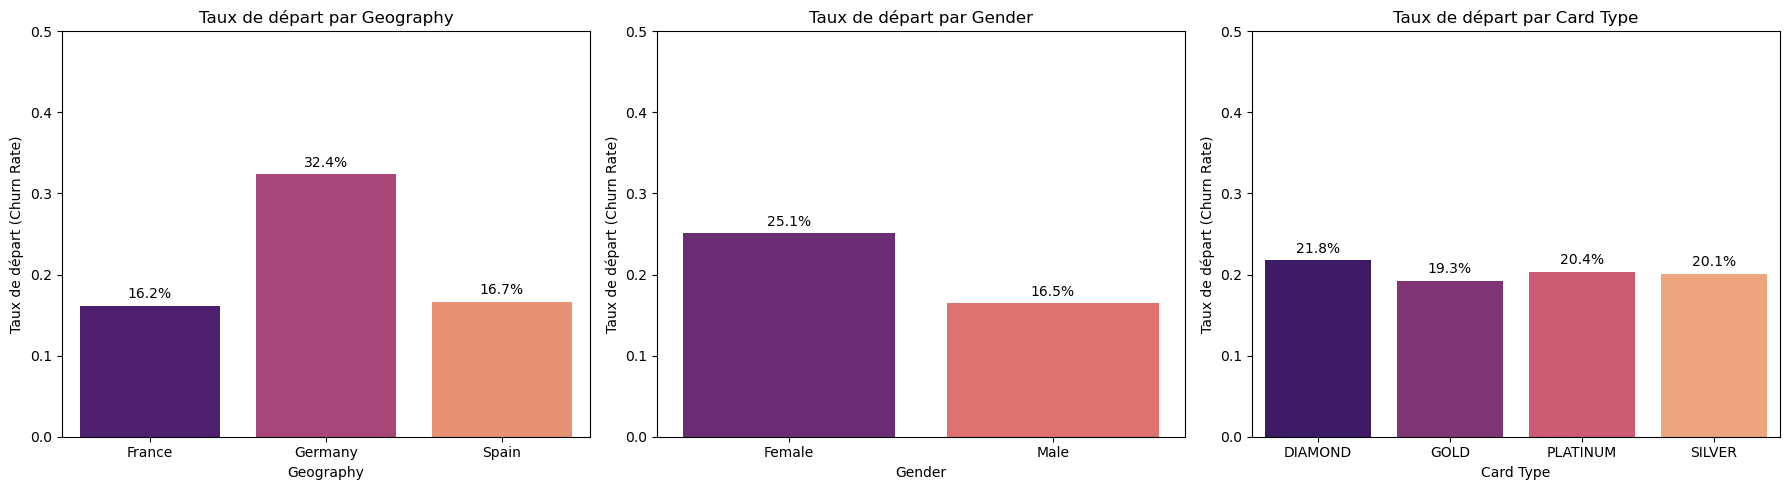

In [109]:
# Liste des variables catégorielles
cat_cols = ['Geography', 'Gender', 'Card Type']

# Création de graphiques en barres pour voir le taux de churn par catégorie
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for i, col in enumerate(cat_cols):
    # Calcul du taux de churn moyen par catégorie
    churn_data = df.groupby(col)['Exited'].mean().reset_index()
   
    # Création du barplot
    sns.barplot(x=col, y='Exited', data=churn_data, ax=axes[i], palette='magma')
   
    # --- AJOUT DES POURCENTAGES ---
    # On récupère le conteneur des barres (il n'y en a qu'un par graphique ici)
    for container in axes[i].containers:
        # On crée les étiquettes en formatant la hauteur de chaque barre en pourcentage
        labels = [f'{v.get_height()*100:.1f}%' for v in container]
        # On ajoute les étiquettes au-dessus des barres (label_type='edge')
        axes[i].bar_label(container, labels=labels, label_type='edge', padding=3)
    # ------------------------------
   
    axes[i].set_title(f'Taux de départ par {col}')
    axes[i].set_ylabel('Taux de départ (Churn Rate)')
    axes[i].set_ylim(0, 0.5) # Pour garder une échelle cohérente

plt.tight_layout()
plt.show()

- quelque chose ne va pas avec l'offre, le service client ou la concurrence en Allemagne, il faut absolument segmenter les analyses par pays 
- les femmes sont plus insatisfaites ou trouvent de meilleures offres ailleurs, il serait interessant de croiser cette variable avec d'autres variables ( pays, nombre de produit détenu)



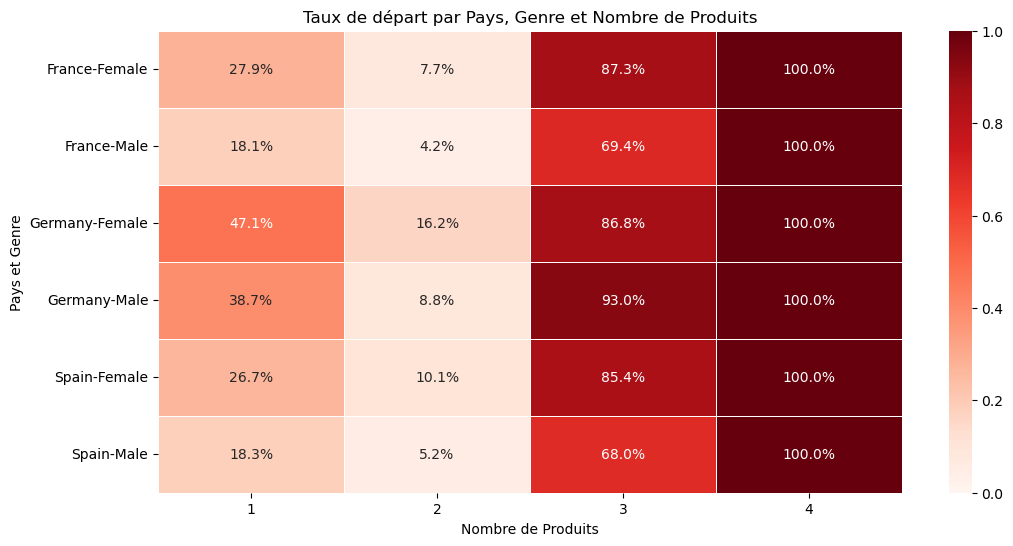

In [110]:
# Calcul d'un tableau croisé dynamique (pivot table)
# On regarde le taux de churn moyen (values='Exited')
pivot_table = df.pivot_table(index=['Geography', 'Gender'],
                             columns='NumOfProducts',
                             values='Exited',
                             aggfunc='mean')

# Affichage sous forme de Heatmap (Carte de chaleur)
plt.figure(figsize=(12, 6))
sns.heatmap(pivot_table, annot=True, cmap='Reds', fmt='.1%', linewidths=.5, vmin=0, vmax=1)
plt.title('Taux de départ par Pays, Genre et Nombre de Produits')
plt.ylabel('Pays et Genre')
plt.xlabel('Nombre de Produits')
plt.show()

Il y a un probleme majeur avec la statégie de vente croisée (cross-selling).  
Pousser les clients à prendre un 3 eme ou 4 eme produit est contre productif.  
Soit ces produits sont de mauvaise qualité, soit ils sont chers, soit ils ne correspondent pas aux besoin et créent de la frustration.

Les clients inactifs ont un taux de départ beaucoup plus élevé

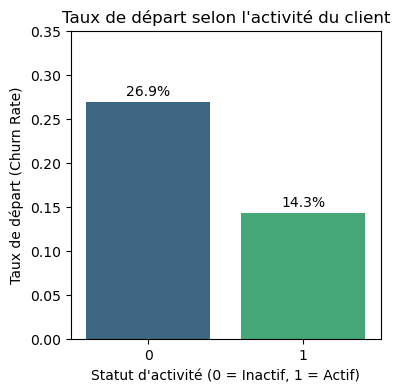

In [111]:
# 1. Calcul du taux de churn par statut d'activité
# 0 = Inactif, 1 = Actif
churn_activite = df.groupby('IsActiveMember')['Exited'].mean().reset_index()

# 2. Création du graphique
plt.figure(figsize=(4, 4))
ax = sns.barplot(x='IsActiveMember', y='Exited', data=churn_activite, palette='viridis')

# 3. Ajout des pourcentages (calcul direct et fiable)
for container in ax.containers:
    labels = [f'{v.get_height()*100:.1f}%' for v in container]
    ax.bar_label(container, labels=labels, label_type='edge', padding=3)

# 4. Personnalisation
plt.title("Taux de départ selon l'activité du client")
plt.xlabel("Statut d'activité (0 = Inactif, 1 = Actif)")
plt.ylabel("Taux de départ (Churn Rate)")
plt.ylim(0, 0.35) # Ajustez selon vos données
plt.show()

Analyse métier : l'inactivité est un signal d'alerte majeur. Un client qui n'utilise pas sa carte ou ses services est un client qui risque de partir.  
Inciter les clients à etre actif est un excellent levier de rétention.

Toutes les personnes ayant portés plaintes sont partis

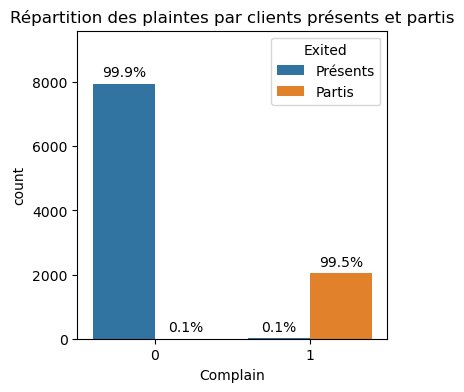

In [112]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Création du graphique
plt.figure(figsize=(4, 4))
ax = sns.countplot(x='Complain', hue='Exited', data=df)

# 2. Calcul des totaux pour chaque catégorie de 'Complain' (0 et 1)
# Cela nous permet de calculer le pourcentage à l'intérieur de chaque groupe
totals = df.groupby('Complain')['Exited'].count().values

# 3. Ajout des pourcentages sur les barres
# On itère sur les conteneurs de barres (un pour 'Exited=0', un pour 'Exited=1')
for i, container in enumerate(ax.containers):
    # Pour chaque conteneur, on calcule le pourcentage de chaque barre par rapport au total de sa catégorie
    # Note: 'totals' est indexé dans le même ordre que les catégories de l'axe x (0 puis 1)
    labels = [f'{(v.get_height() / totals[int(v.get_x() + v.get_width()/2)]) * 100:.1f}%' for v in container]
   
    # On ajoute les étiquettes au-dessus des barres
    ax.bar_label(container, labels=labels, label_type='edge', padding=3)

# 4. Personnalisation (comme dans votre code original)
plt.title("Répartition des plaintes par clients présents et partis")
new_labels = ['Présents', 'Partis']
plt.legend(labels=new_labels, title='Exited')

# Ajustement de la limite de l'axe Y pour que les étiquettes ne soient pas coupées en haut
plt.ylim(0, ax.get_ylim()[1] * 1.15)

plt.show()

Presque toutes les personnes ayant portés plaintes sont partis, 
Donc la variable complain qui indique si le client a fait une réclamation corespond à la variable cible Exited dans 99.86% des cas.  
Autrement dit cette variable n'explique pas le départ du client : elle l'enregistre, probablement au moment meme ou il quitte la banque.  
On doit exclure la variable Complain de la modélisation car si on la garde on aura obtenu un score presque parfait, mais totalement inutile en pratique parceque cette information n'existe pas avant que le client parte.  

4. STEP 4 : PRETRAITEMENT

In [113]:
# Suppression de la colonne Complain
df_clean = df_2.drop('Complain', axis=1)

In [114]:
df_clean.head()

,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Satisfaction Score,Card Type,Point Earned
0,619,France,Female,42,2,0.00,1,1,1,101348.88,1,2,DIAMOND,464
1,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0,3,DIAMOND,456
2,502,France,Female,42,8,159660.80,3,1,0,113931.57,1,3,DIAMOND,377
3,699,France,Female,39,1,0.00,2,0,0,93826.63,0,5,GOLD,350
4,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0,5,GOLD,425


In [115]:
# Separate target variable Y from features X
X = df_clean.drop(columns=["Exited"], axis=1)
y = df_clean[["Exited"]]
display(X.head(3))
display(y.head(3))


,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Satisfaction Score,Card Type,Point Earned
0,619,France,Female,42,2,0.00,1,1,1,101348.88,2,DIAMOND,464
1,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,3,DIAMOND,456
2,502,France,Female,42,8,159660.80,3,1,0,113931.57,3,DIAMOND,377


,Exited
0,1
1,0
2,1


In [116]:
# Divide dataset Train set & Test set 

X_train, X_test, y_train, y_test = train_test_split(X, y, 
                                                    test_size=0.2, 
                                                    random_state=42, stratify=y)
print("...Done.")

...Done.


In [117]:
for i, col in enumerate(X.columns):
    print(f"Colonne {i}: {col}")

Colonne 0: CreditScore
Colonne 1: Geography
Colonne 2: Gender
Colonne 3: Age
Colonne 4: Tenure
Colonne 5: Balance
Colonne 6: NumOfProducts
Colonne 7: HasCrCard
Colonne 8: IsActiveMember
Colonne 9: EstimatedSalary
Colonne 10: Satisfaction Score
Colonne 11: Card Type
Colonne 12: Point Earned


In [118]:
### Training pipeline ###
print("--- Training pipeline ---")
print()  

# Encoding categorical features and standardizing numeric features

print("#### X_train BEFORE preprocessing ####")
print(X_train.head())
print()

print("Encoding categorical features and standardizing numerical features...")
## First let's import libraries
## StandardScaler to scale data (i.e apply Z-score)
## OneHotEncoder to encode categorical variables


numeric_features = [0, 3, 4, 5, 6, 7, 8, 9, 10, 12] # Choose which column index we are going to scale
numeric_transformer = StandardScaler()

categorical_features = [1, 2, 11] # Choose which column index we are going to encode
categorical_transformer = OneHotEncoder()

# Apply ColumnTransformer to create a pipeline that will apply the above preprocessing
feature_encoder = ColumnTransformer(
    transformers=[
        ('cat', categorical_transformer, categorical_features),    
        ('num', numeric_transformer, numeric_features)
        ]
    )

X_train = feature_encoder.fit_transform(X_train)
print("...Done.")
print("#### X_train AFTER preprocessing ####")
print(X_train[0:5,:]) # print first 5 rows (not using iloc since now X_train became a numpy array)
print()


--- Training pipeline ---

#### X_train BEFORE preprocessing ####
      CreditScore Geography  Gender  Age  Tenure    Balance  NumOfProducts  \
4791          709     Spain    Male   35       2       0.00              2   
8881          744    France    Male   29       1   43504.42              1   
6166          773    France    Male   64       2  145578.28              1   
4473          646   Germany  Female   29       4  105957.44              1   
854           675    France  Female   57       8       0.00              2   

      HasCrCard  IsActiveMember  EstimatedSalary  Satisfaction Score  \
4791          1               0        104982.39                   2   
8881          1               1        119327.75                   1   
6166          0               1        186172.85                   1   
4473          1               0         15470.91                   1   
854           0               1         95463.29                   3   

     Card Type  Point Earned  
4

In [119]:
### Test pipeline ###
print("--- Test pipeline ---") 

# Encoding categorical features and standardizing numeric features
print("Encoding categorical features and standardizing numerical features...")
print()

X_test = feature_encoder.transform(X_test)
print("...Done.")

print("#### X_test AFTER preprocessing ####")
print(X_test[0:5,:])
print()



--- Test pipeline ---
Encoding categorical features and standardizing numerical features...

...Done.
#### X_test AFTER preprocessing ####
[[ 0.          1.          0.          1.          0.          0.
   0.          0.          1.         -0.44108724 -0.08787439  1.03493712
   0.43670885  0.8067009   0.64298333  0.96728484  0.65407575 -0.00779989
   1.04794542]
 [ 1.          0.          0.          0.          1.          1.
   0.          0.          0.          0.36561412 -0.18263043  1.38092529
   0.93277597 -0.91059745  0.64298333 -1.03382164 -1.25246844 -1.42596179
   0.04821646]
 [ 0.          0.          1.          1.          0.          0.
   1.          0.          0.          0.01397507  0.29114979 -0.34901557
  -1.22695683  0.8067009   0.64298333  0.96728484 -1.06865296  1.41036201
  -1.66370879]
 [ 1.          0.          0.          1.          0.          0.
   0.          1.          0.          0.4793797   0.57541792 -1.38698009
  -1.22695683  0.8067009   0.64298

MACHINE LEARNING 

5. STEP 5 : LOGISTIC REGRESSION

In [120]:
# Build a logistic Regression
# Training model 
print("Training model...")
classifier = LogisticRegression(random_state = 0,class_weight='balanced', max_iter=1000) 
classifier.fit(X_train, y_train) 
print("...Done.")

Training model...
...Done.


In [121]:
# Predictions on training set
print("Predictions on train set...")
y_train_pred = classifier.predict(X_train)
print("...Done.")
print()

print("#### First five predictions on TRAIN set ####")
print(y_train_pred[0:5])


Predictions on train set...
...Done.

#### First five predictions on TRAIN set ####
[0 0 1 1 1]


In [122]:
# Predictions on testing set
print("Predictions on test set...")
y_test_pred = classifier.predict(X_test)
print("...Done.")
print()

print("#### First five predictions on TEST set ####")
print(y_test_pred[0:5])


Predictions on test set...
...Done.

#### First five predictions on TEST set ####
[1 0 0 1 0]


In [123]:
print ("Accuracy on training set :",accuracy_score(y_train, y_train_pred))
print ("Accuracy on test set :",accuracy_score(y_test, y_test_pred))

Accuracy on training set : 0.710375
Accuracy on test set : 0.7115


Analyse : 71.1% est un score correct, mais pas excellent en matière de prédiction de churn 

--- Assessment of performances ---


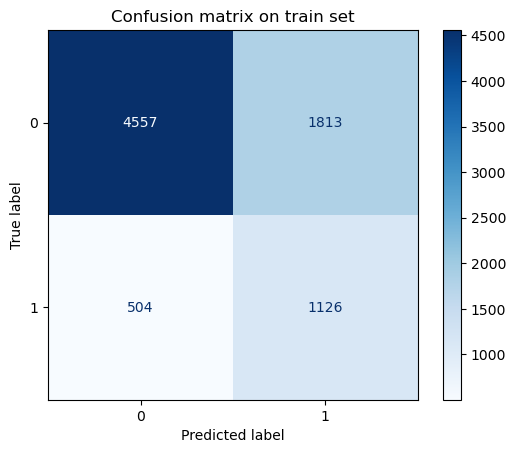

accuracy-score on train set :  0.710375


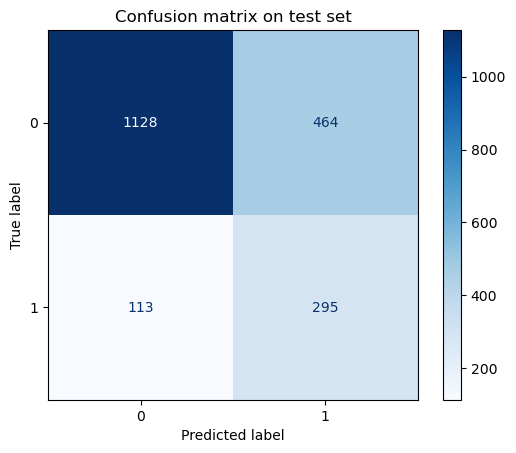

accuracy-score on test set :  0.7115


In [124]:
# Evaluate The model
### Assessment of performances ###
print("--- Assessment of performances ---")

# Plot confusion matrix
ConfusionMatrixDisplay.from_estimator(
    classifier,                 # fitted model
    X_train, y_train,           # data + labels
    cmap=plt.cm.Blues,          # any matplotlib colormap
    normalize=None              # "true", "pred", "all", or None
)
plt.title("Confusion matrix on train set")
plt.show()
print("accuracy-score on train set : ", classifier.score(X_train, y_train))


ConfusionMatrixDisplay.from_estimator(
    classifier,
    X_test, y_test,
    cmap=plt.cm.Blues
)
plt.title("Confusion matrix on test set")
plt.show()
print("accuracy-score on test set : ", classifier.score(X_test, y_test))



Analyse des matrices : le modele est sensible il prédit qu'il y aura 759 départs alors qu'il n'y en a eu que 408 dans la réalité, il sur-prédit le churn  
la force du modele : 295/(295+113)=0.723(soit72.3%)il arrive à detecter 72% des clients qui partent réellement.  
La faiblesse du modele : 295/(295+464)=0.388 (soit38.8%) quand le modele dit ce client va partir , il n'a raison que 38.8% du temps. donc il y a beaucoup de fausse alerte  
ce modele n'est pas optimal car il gaspille des ressources sur 464 clients 

In [125]:
# Récupérer les noms des colonnes après l'encodage OneHotEncoder
feature_names = feature_encoder.get_feature_names_out()
# récupérer les coefficients du modele de régression logstique 
coefficients = classifier.coef_[0]
# Créer un DataFrame pour visualiser les coefficients avec leurs noms de colonnes
feature_importance = pd.DataFrame({'feature_names': feature_names, 'coefficients': coefficients})
# Nettoyer les noms (enlever 'cat__' et 'num__' pour que ce soit plus lisible)
feature_importance['feature_names'] = feature_importance['feature_names'].str.replace('cat__', '').str.replace('num__', '')

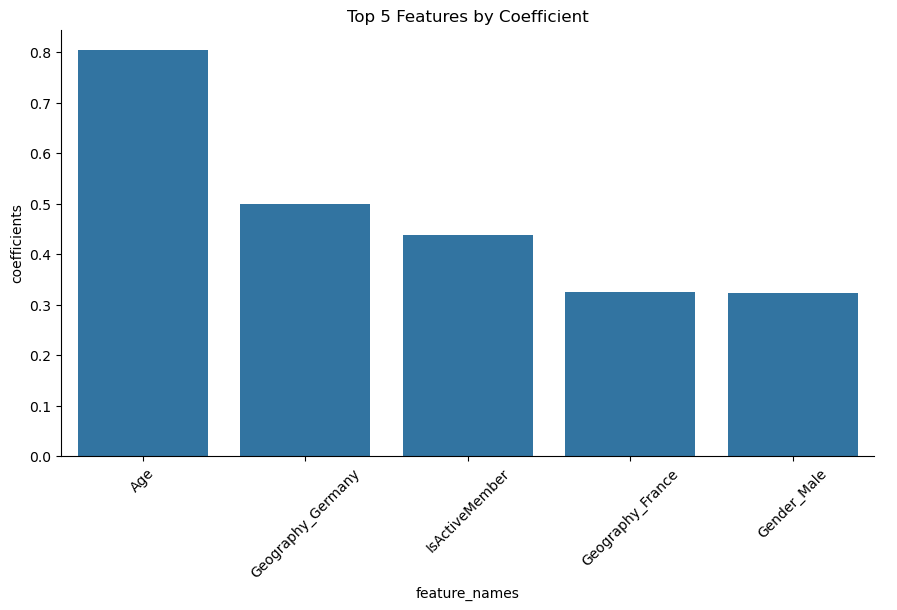

In [126]:
# prendre la valeur absolue des coefficients pour les classer par importance
feature_importance["coefficients"] = feature_importance["coefficients"].abs()

# Visualize ranked features using seaborn
sns.catplot(x="feature_names", 
            y="coefficients", 
            data=feature_importance.sort_values(by="coefficients", ascending=False).head(5), 
            kind="bar",
            aspect=16/9) # Resize graph

plt.xticks(rotation=45)
plt.title("Top 5 Features by Coefficient")
plt.show()


Les 5 variables les plus influentes pour prédir le départ d'un client,   
Le modele confirme nos hypothese métier. Pour retenir nos clients, nous devons cibler en prioritè les clients agés, les clients allemands et les membres inactifs

6. STEP 6 : RANDOM FOREST

In [135]:
from sklearn.ensemble import RandomForestClassifier


classifier = RandomForestClassifier( 
    n_estimators=300,
    class_weight = 'balanced',
    random_state=42,
    n_jobs= -1,
    max_depth=8)
classifier.fit(X_train, y_train)
print('...Done.')

...Done.


In [136]:
# Prediction  :
y_pred_train = classifier.predict(X_train)
print('y_pred_train....Done.')
print(y_pred_train[0:5])
y_pred_test = classifier.predict(X_test)
print('y_pred_test....Done.')
print(y_pred_test[0:5])

y_pred_train....Done.
[0 0 0 1 0]
y_pred_test....Done.
[0 0 0 0 0]


In [137]:
# Evaluation des performances : 

# Print scores :
print("Accuracy on training set : ", accuracy_score(y_train, y_pred_train))
print("Accuracy on test set : ", accuracy_score(y_test, y_pred_test))

Accuracy on training set :  0.868375
Accuracy on test set :  0.823


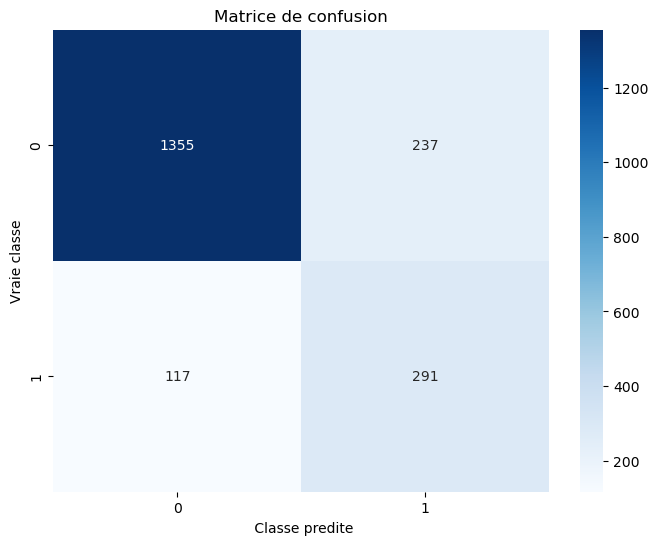

In [140]:
# Matrice de confusion :
cm = confusion_matrix (y_test, y_pred_test)
plt.figure(figsize=(8,6))
sns.heatmap(cm,annot=True,fmt='d',cmap ='Blues')
plt.title('Matrice de confusion')
plt.ylabel('Vraie classe')
plt.xlabel(' Classe predite')
plt.show()

Analyse de la matrice : rappel classe 1 : vp/(vp+fn)=71.3% sur 100 clients qui vont partir le modele detecte 71 il rate que 29 c'est un excellent score pour un probleme churn

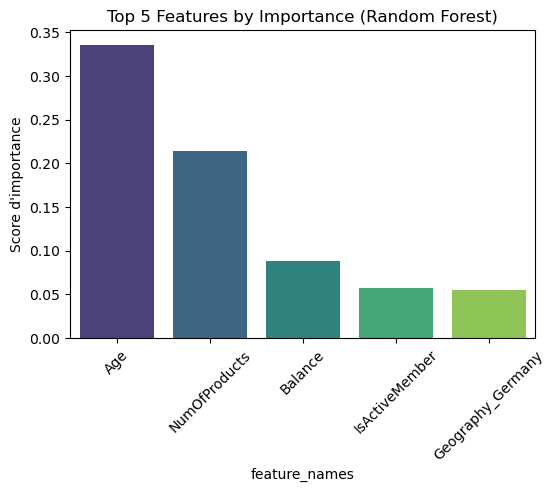

In [142]:
# 1. Récupérer les noms des colonnes après prétraitement (OneHotEncoder)
feature_names = feature_encoder.get_feature_names_out()

# 2. Récupérer l'importance des variables depuis le Random Forest
# 'classifier' est votre modèle Random Forest entraîné
importances = classifier.feature_importances_

# 3. Créer le DataFrame
feature_importance_rf = pd.DataFrame({
    'feature_names': feature_names,
    'importance': importances
})

# 4. Nettoyer les noms (enlever 'cat__' et 'num__')
feature_importance_rf['feature_names'] = feature_importance_rf['feature_names'].str.replace('cat__', '').str.replace('num__', '')

# 5. Trier et prendre le Top 5
top_5_rf = feature_importance_rf.sort_values(by='importance', ascending=False).head(5)

# 6. Visualisation
plt.figure(figsize=(6, 4))
sns.barplot(x='feature_names', y='importance', data=top_5_rf, palette='viridis')
plt.title('Top 5 Features by Importance (Random Forest)')
plt.ylabel("Score d'importance")
plt.xticks(rotation=45)
plt.show()

## Comparaison finale : Random Forest Vs Regression logistique


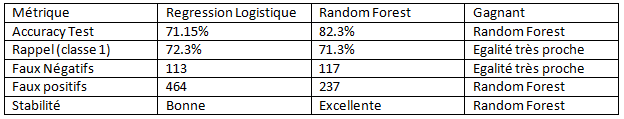


# Analyse métier :  
Le RF est bien plus précis que la RL, il ne fait que 237 fausses alertes (faux positifs) contre 464 pour RL  
Cela signifie que pour un cout marketing identique, le RF permet de cibler les clients à risque de manière beaucoup plus efficace, tout en détectant 71% des départs réels (rappel)  
Donc c'est le modele qu'on recommande pour la mise en production  
  
## Recommandations Stratégiques

1. Bilan du Modèle (Le Choix)

· Modèle retenu : Random Forest (avec class_weight='balanced' et hyperparamètres optimisés).  
· Performance : 82% d'accuracy, 71% de Rappel sur les départs.  
· Pourquoi lui ? Il est plus stable et détecte mieux les clients à risque que la Régression Logistique, tout en réduisant les fausses alertes (Faux Positifs).  
· Top 5 des facteurs de départ : 1. Âge, 2. Nombre de produits, 3. Solde, 4. Inactivité, 5. Allemagne.  

2. Recommandations Opérationnelles (Les 3 Actions Clés)

· Action 1 : Cibler les clients de 45-55 ans et les inactifs.  

  · Pourquoi ? Ce sont les profils qui partent le plus.  
  · Comment ? Campagnes de réengagement personnalisées pour les membres inactifs et offres de fidélisation pour les quadragénaires.  

· Action 2 : Auditer d'urgence la vente de 3 produits ou plus.  

  · Pourquoi ? Le modèle a montré que le nombre de produits est le 2ème facteur de départ. Les clients avec 3 ou 4 produits partent massivement (souvent à 100%).  
  · Comment ? Arrêter de pousser la vente de 3ème produit. Auditer la qualité et le prix de ces produits pour comprendre cette fuite.  

· Action 3 : Concentrer les efforts sur le marché allemand.  

  · Pourquoi ? L'Allemagne ressort comme un facteur de risque majeur (surtout pour les femmes).  
  · Comment ? Enquête de satisfaction locale et révision de l'offre bancaire en Allemagne.  
